# Indigenous Wholistic Factors Project: Live Room Vote Demonstration

**This notebook runs on synthetic data, not real youth responses.** Every respondent here is simulated. The results show how the method behaves. They are not findings about Native American youth.

A room votes on which California Healthy Kids Survey (CHKS) factors belong in a model predicting past-year suicidal ideation. The room's top-voted items then go into a LASSO logistic regression, following the structure of the [IWFP notebook and Stata scripts](../scripts/primary_analysis.do) from:

Sierra VQ (2025). Predicting Suicidal Ideation Among Native American High Schoolers in California. *Archives of Suicide Research* 30(1):80-97. [PMC12424082](https://pmc.ncbi.nlm.nih.gov/articles/PMC12424082/)

| | In this notebook | In the published study |
|---|---|---|
| Data | Synthetic, 2,609 fake respondents calibrated to published totals | CHKS 2019-20, not shared |
| Who chose the predictors | The people in this room | Community partners and the study team |
| Software | Python, scikit-learn | Stata 17 |

**The saved copy on GitHub shows rehearsal votes.** To run it live, choose Run All.

# Setup

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import inspect
import os

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import figures as fig
import iwfp_reference as iwfp
import load_votes as lv
import pipeline as pl
import synthetic_data as sd

# The board to read. The saved copy on GitHub was run with IWFP_DEMO_BOARD=nov4-rehearsal.
BOARD_ID = os.environ.get("IWFP_DEMO_BOARD", "nov4-talk")
TOP_N = 30          # the room's top 30, ties kept. 0 = every item with a vote.

# Leave as None for live votes. Set to a file to use it instead:
#   "paper_tally.csv"        a copy of paper_tally_template.csv with the sticky-dot counts typed in
#   "rehearsal_votes.csv"    rehearsal votes (tell the room these aren't theirs)
RESULTS_CSV = None

pd.set_option("display.max_rows", 120, "display.max_colwidth", 70)

# Votes from the room

Votes load first and are saved to `results/` straight away, so a dropped connection after this point doesn't matter.

In [2]:
votes, source = lv.load_votes(BOARD_ID, RESULTS_CSV)
ranked, ties_extended = lv.top_voted(votes, TOP_N)
candidates = ranked["item_id"].tolist()
labels = lv.LABELS

display(Markdown(f"**{source}**"))
print(f"{votes['vote_count'].sum()} dots on {(votes['vote_count'] > 0).sum()} of {len(votes)} items.")
print(f"{len(candidates)} items go into the model."
      + (f" Ties at #{TOP_N} were kept." if ties_extended else ""))

**Live votes from board 'nov4-rehearsal'. Saved to results/.**

37 dots on 29 of 84 items.
29 items go into the model.


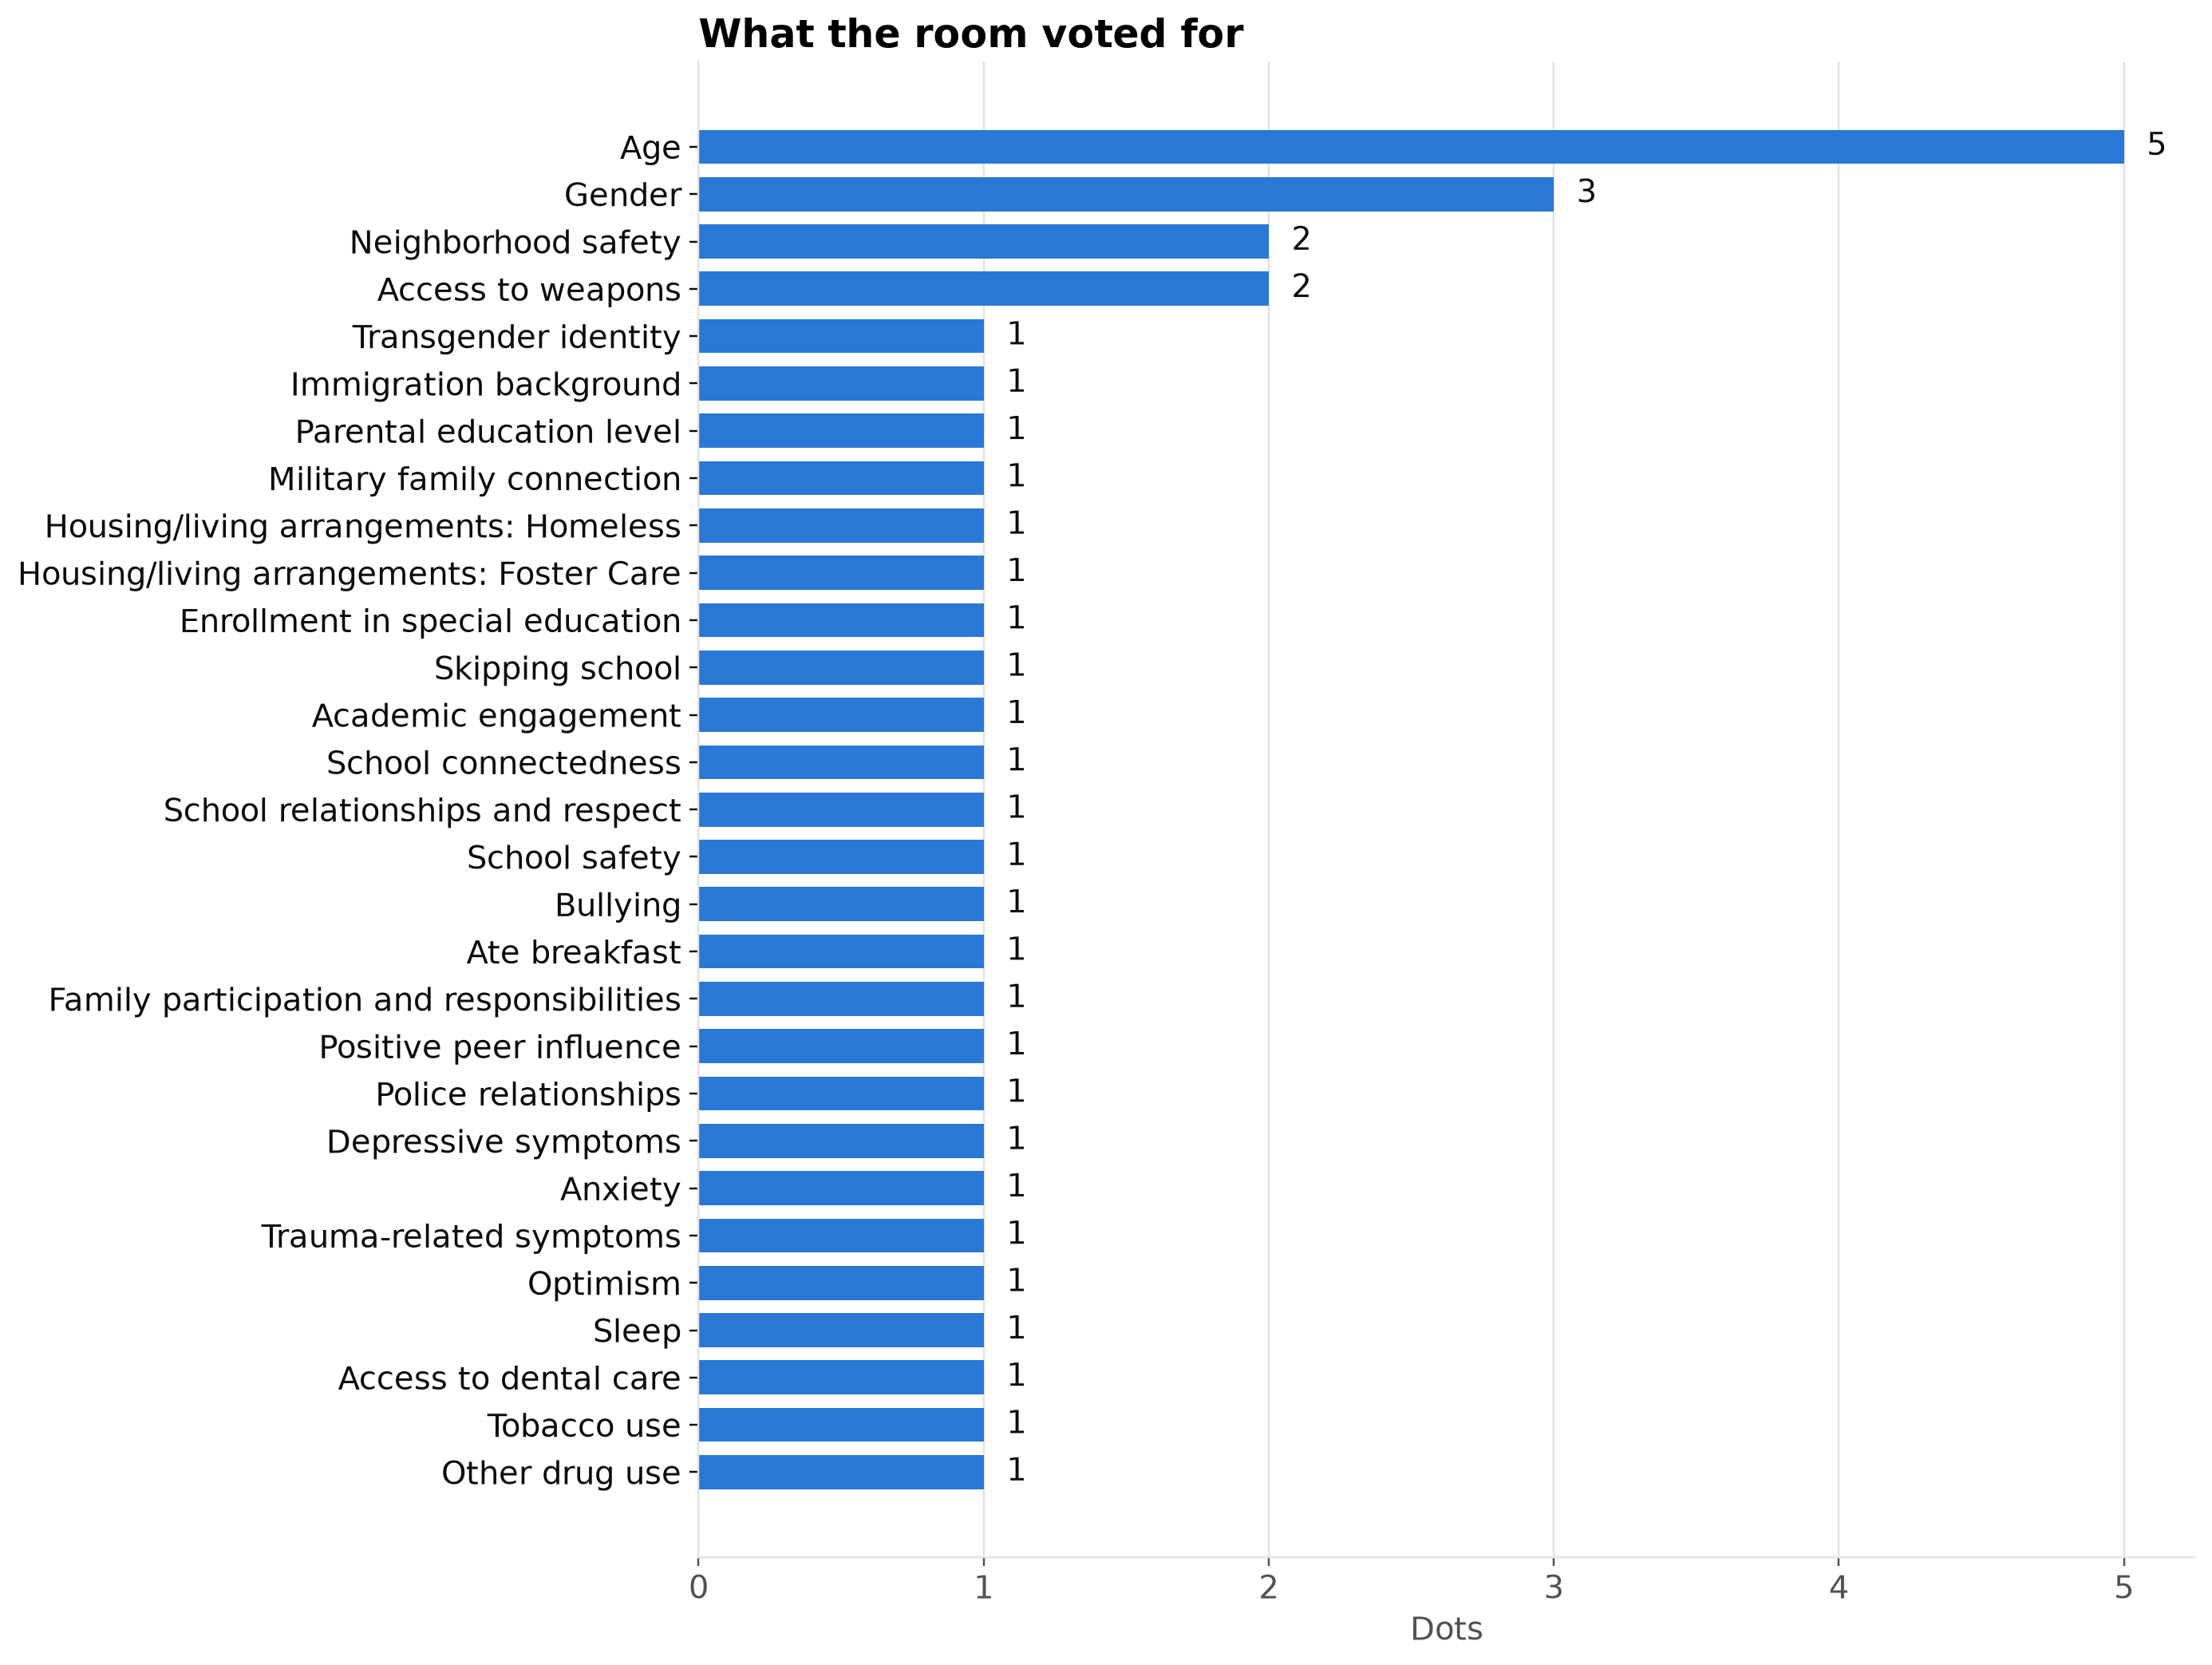

In [3]:
fig.votes_chart(ranked);

# Dataset

Real CHKS data are privacy-protected, and their sensitive items shouldn't be run live in a room. This dataset is simulated, so the room can see the whole process with no real respondent involved.

Real survey items cluster, so each fake respondent gets five correlated underlying factors, and every item is a noisy reflection of one or more of them.

In [4]:
pd.DataFrame(sd.FACTOR_CORR,
             index=["Distress", "Victimization", "Substance", "Connectedness", "Adversity"],
             columns=["Distress", "Victimization", "Substance", "Connectedness", "Adversity"])

,Distress,Victimization,Substance,Connectedness,Adversity
Distress,1.00,0.40,0.25,-0.35,0.15
Victimization,0.40,1.00,0.35,-0.25,0.15
Substance,0.25,0.35,1.00,-0.20,0.15
Connectedness,-0.35,-0.25,-0.20,1.00,-0.15
Adversity,0.15,0.15,0.15,-0.15,1.00


## The code that builds it

The full item settings are in [`synthetic_data.py`](synthetic_data.py). The random seed follows a stated rule, so this rebuilds the same dataset every time.

In [5]:
display(Markdown("```python\n" + inspect.getsource(sd.generate) + "```"))

```python
def generate(n_respondents: int = N_RESPONDENTS, seed: int = DEFAULT_SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    item_ids = load_item_ids()
    unspecified = set(item_ids) - set(ITEM_SPECS) - {"age", "grade"}
    if unspecified:
        raise ValueError(f"No synthetic spec for item(s): {sorted(unspecified)}")

    latent = rng.multivariate_normal(np.zeros(len(FACTORS)), FACTOR_CORR, size=n_respondents)
    factors = {f: latent[:, i] for i, f in enumerate(FACTORS)}

    data: dict[str, np.ndarray] = {}
    # Demographics that shift the latent factors come first.
    for item_id in ("gender", "transgender", "lgb"):
        (_, p), _ = ITEM_SPECS[item_id]
        data[item_id] = (rng.random(n_respondents) < p).astype(int)
    # Minority stress and internalizing differences (directions from the
    # literature; sizes are demo settings).
    factors["D"] = factors["D"] + 0.35 * data["lgb"] + 0.40 * data["transgender"] + 0.15 * data["gender"]
    factors["V"] = factors["V"] + 0.30 * data["lgb"] + 0.35 * data["transgender"]

    grade = rng.choice([9, 10, 11, 12], size=n_respondents, p=[0.27, 0.26, 0.24, 0.23])
    data["grade"] = grade
    data["age"] = np.clip(grade + 5 + rng.choice([0, 0, 0, 1, -1], size=n_respondents), 13, 18)

    for item_id in item_ids:
        if item_id in data:
            continue
        (kind, spec), loadings = ITEM_SPECS[item_id]
        x = _indicator(factors, loadings, rng, n_respondents)
        probs = [1 - spec, spec] if kind == "binary" else spec
        data[item_id] = _cut(x, probs)

    df = pd.DataFrame({item_id: data[item_id] for item_id in item_ids})

    lin = sum(w * factors[f] for f, w in SI_LATENT_EFFECTS.items())
    lin = lin + sum(w * df[item] for item, w in SI_DIRECT_EFFECTS.items())
    lin = np.asarray(lin, dtype=float)
    # Choose the intercept so expected prevalence matches IWFP's 16.8%.
    lo, hi = -10.0, 10.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(mid + lin)))).mean() > SI_PREVALENCE:
            hi = mid
        else:
            lo = mid
    p_si = 1 / (1 + np.exp(-(lo + lin)))
    df[OUTCOME_ITEM] = rng.binomial(1, p_si)
    return df
```

In [6]:
df = sd.generate()
print(f"{len(df):,} synthetic respondents, {df.shape[1] - 1} items plus the outcome")
df.head()

2,609 synthetic respondents, 84 items plus the outcome


,age,grade,race,gender,transgender,lgb,immigration_background,language,parental_education,military_family,...,screen_time,body_image,tobacco_use,vaping,alcohol_use,cannabis_use,other_drug_use,substance_risk_perceptions,substance_access,si
0,14,9,0,1,0,0,0,1,0,1,...,4,0,0,0,0,0,0,3,0,0
1,16,11,1,0,0,1,0,0,1,0,...,2,3,0,0,0,1,0,0,3,0
2,16,10,0,1,0,0,0,0,0,0,...,4,0,0,1,0,0,0,0,2,0
3,14,9,0,0,0,1,0,0,4,0,...,4,1,0,0,0,0,0,3,1,0
4,17,12,1,0,0,0,0,0,0,0,...,2,0,0,0,1,0,0,0,3,0


## How close it is to the published sample

These totals are what the simulation was calibrated to. Matching them says nothing about whether any individual-level pattern is real.

In [7]:
pd.DataFrame(
    [{"Characteristic": name, "Published IWFP (%)": pct, "Synthetic (%)": round(df[col].mean() * 100, 2)}
     for name, col, pct in iwfp.TABLE_1]
)

,Characteristic,Published IWFP (%),Synthetic (%)
0,Past-year suicidal ideation,16.80,16.98
1,Female,50.60,50.48
2,Transgender,2.95,2.76
3,Sexual minority,17.00,16.75
4,Depressive symptoms,40.00,40.02
5,Foster care,0.34,0.34
6,Homeless,2.53,2.53
7,Ate breakfast,55.00,55.00


# Binary Variable Outcomes

## Suicidal Ideation

In the published study, this is the CHKS item on seriously considering suicide in the past 12 months. Here it is simulated, and it isn't on the voting board because it's what the model predicts.

In [8]:
pd.DataFrame({"Respondents": df["si"].value_counts().sort_index(),
              "Percent": (df["si"].value_counts(normalize=True).sort_index() * 100).round(1)}
             ).rename(index={0: "No SI", 1: "SI"})

,Respondents,Percent
si,,
No SI,2166,83.0
SI,443,17.0


# Predictor Variables

IWFP organized its 17 predictors by Indigenous Wholistic domain. This table shows how the room's votes line up with them, and whether the published model retained each one. The published study had no predictors in the Spiritual-Historical domain.

The other board items weren't in IWFP's model, so they have no domain here. Assigning them one is a decision for a community process, not this notebook.

In [9]:
vote_lookup = votes.set_index("item_id")["vote_count"]
domains = iwfp.PREDICTORS.assign(
    room_votes=lambda t: t["item_id"].map(vote_lookup).fillna(0).astype(int),
    in_room_model=lambda t: t["item_id"].isin(candidates).map({True: "Yes", False: "No"}),
    published_retained=lambda t: t["published_retained"].map({True: "Yes", False: "No"}),
)[["domain", "predictor", "room_votes", "in_room_model", "published_retained"]]
domains.columns = ["Domain", "IWFP predictor", "Room's dots", "In room's model", "Retained in published model"]
overlap = iwfp.PREDICTORS["item_id"].isin(candidates).sum()
print(f"The room chose {overlap} of IWFP's 17 predictors, plus {len(candidates) - overlap} that IWFP didn't include.")
domains

The room chose 10 of IWFP's 17 predictors, plus 19 that IWFP didn't include.


,Domain,IWFP predictor,Room's dots,In room's model,Retained in published model
0,Individual,Gender,3,Yes,No
1,Individual,Gender minority status,1,Yes,Yes
2,Individual,Sexual minority status,0,No,Yes
3,Individual,Academic performance,0,No,No
4,Individual,Lifetime alcohol use,0,No,Yes
5,Individual,Lifetime cigarette use,1,Yes,No
6,Individual,Lifetime vape use,0,No,Yes
7,Individual,Lifetime cannabis use,0,No,Yes
8,Individual,Lifetime other drug use,1,Yes,No
9,Emotional-Social,Foster care placement,1,Yes,No


# Analysis

## Fit the Model

LASSO logistic regression on standardized items, so odds ratios are per 1 standard deviation.

**Differences from `primary_analysis.do`:** the published model used Stata's `lasso logit, selection(cv)`. This one uses the one-standard-error rule, a stricter penalty, because tuning for best AUC alone let noise items survive with small effects. It also adds a bootstrap check. An item counts as a finding only if it's kept, its odds ratio is outside 0.98 to 1.02, and it's kept in at least 70 of 100 resamples.

In [10]:
result = pl.run_lasso(df, candidates)
print(f"Kept {len(result['selected_features'])} of {len(candidates)} candidates. "
      f"Nested cross-validated AUC: {result['cv_auc_mean']:.3f} (+/- {result['cv_auc_std']:.3f})")

Kept 9 of 29 candidates. Nested cross-validated AUC: 0.886 (+/- 0.016)


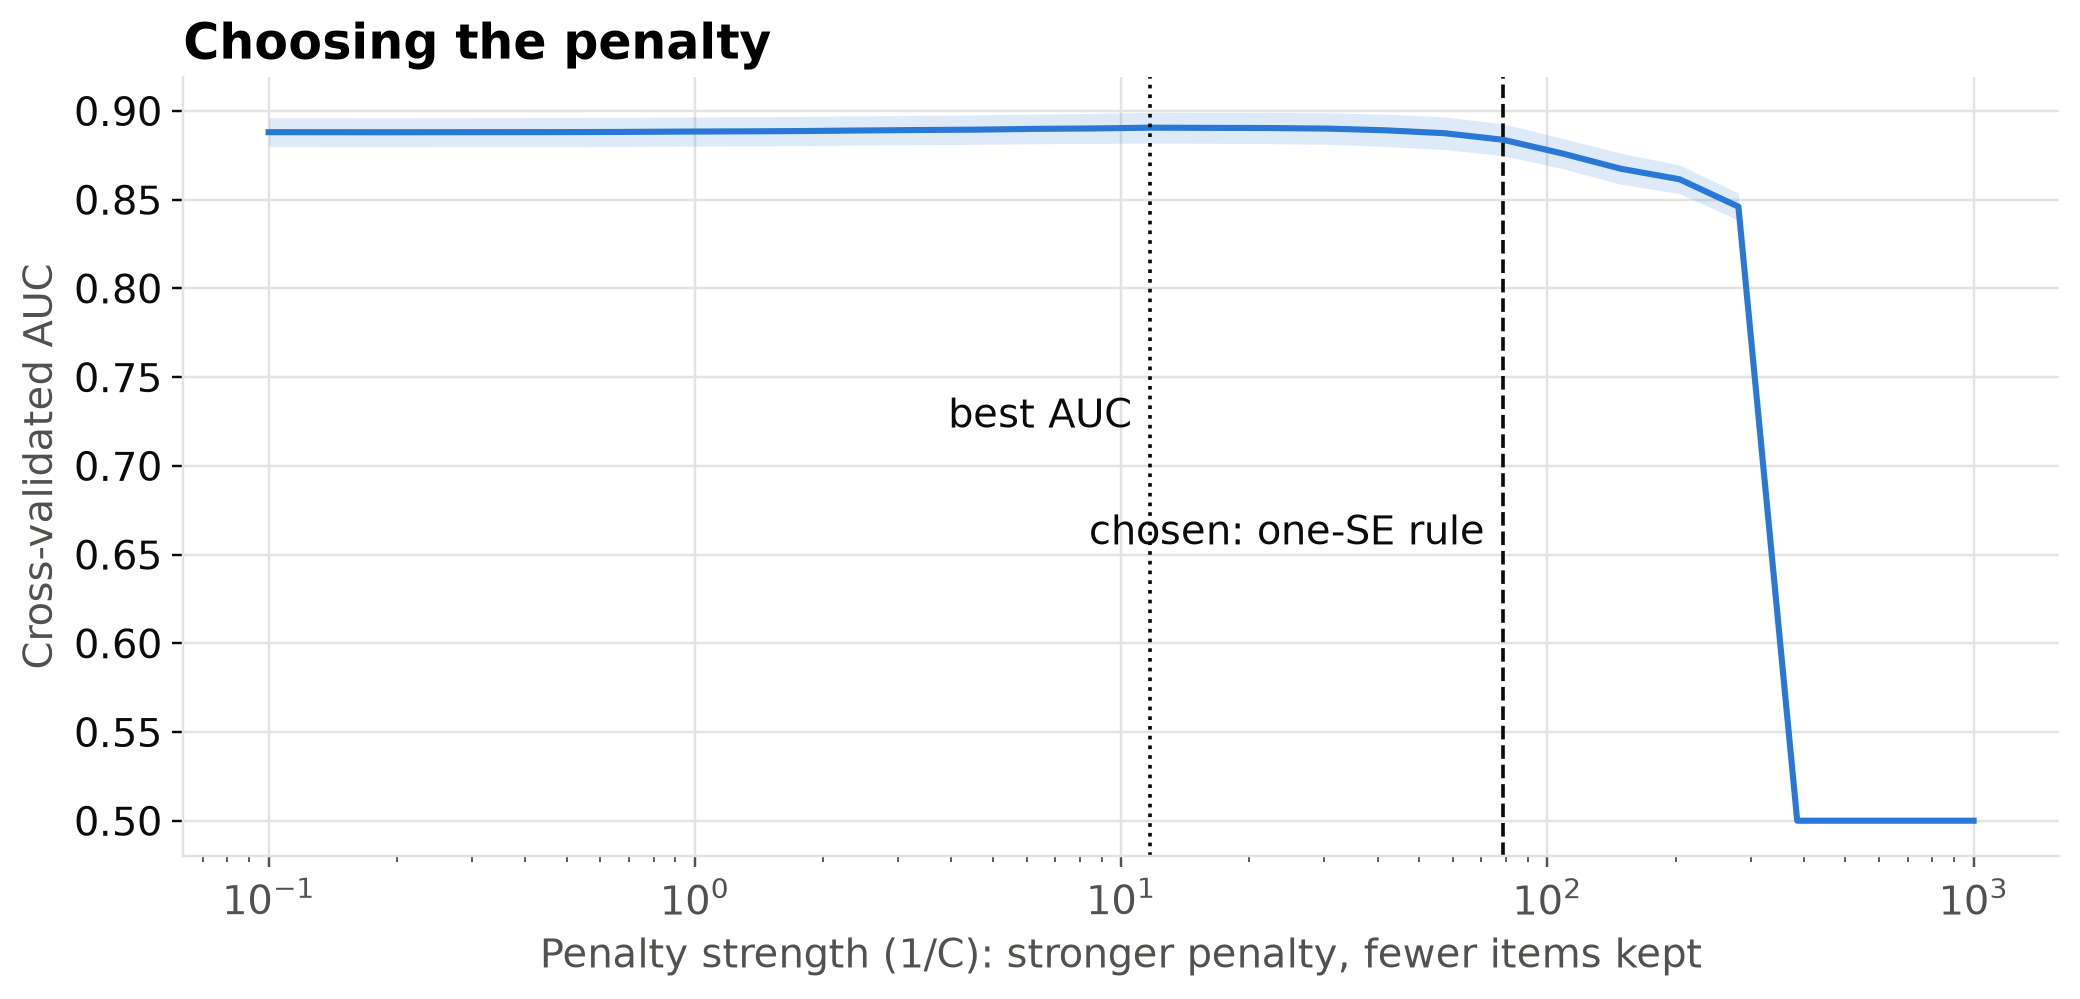

In [11]:
curve = pl.cv_curve(df, candidates)
fig.cv_chart(curve);

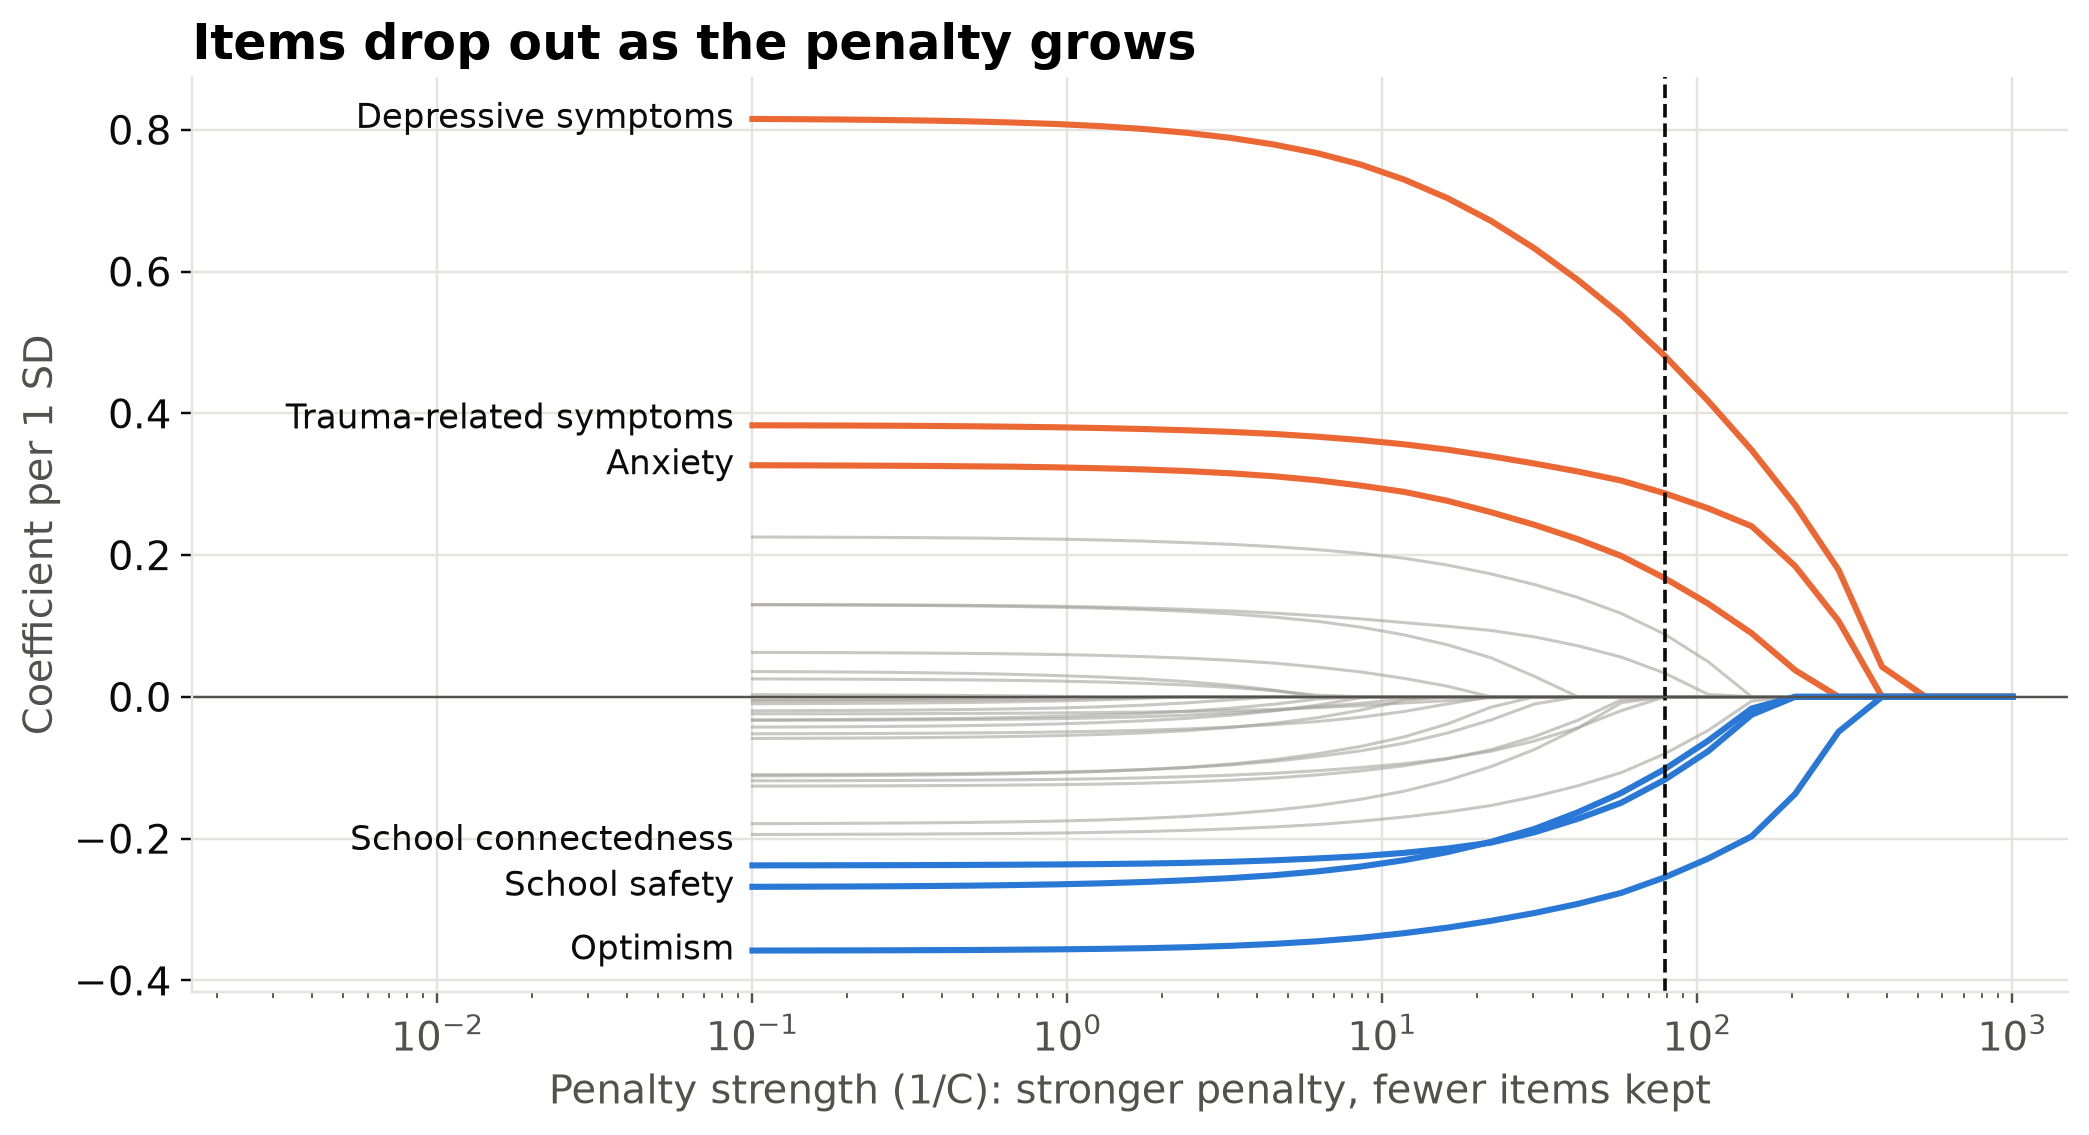

In [12]:
fig.path_chart(pl.coefficient_path(df, candidates), curve, labels);

## Coefficients

The equivalent of `lassocoef, display(coef, standardized)`.

In [13]:
coef_table = pd.DataFrame([
    {"Item": labels.get(f, f),
     "Dots": int(ranked.set_index("item_id").loc[f, "vote_count"]),
     "Odds ratio per SD": result["odds_ratios"][f] if f in result["selected_features"] else None,
     "Kept in resamples": f"{result['stability'][f]:.0%}",
     "Result": pl.classify(result, f)}
    for f in candidates
])
order = {"higher risk": 0, "protective": 1, "weak or unstable": 2, "dropped": 3}
coef_table = coef_table.sort_values(["Result", "Odds ratio per SD"], key=lambda c: c.map(order) if c.name == "Result" else c,
                                    ascending=[True, False], na_position="last").reset_index(drop=True)
coef_table

,Item,Dots,Odds ratio per SD,Kept in resamples,Result
0,Depressive symptoms,1,1.618,100%,higher risk
1,Trauma-related symptoms,1,1.333,100%,higher risk
2,Anxiety,1,1.182,100%,higher risk
3,Bullying,1,1.092,93%,higher risk
4,Skipping school,1,1.034,71%,higher risk
5,School relationships and respect,1,0.923,90%,protective
6,School safety,1,0.903,99%,protective
7,School connectedness,1,0.890,96%,protective
8,Optimism,1,0.775,100%,protective
9,Age,5,NaN,0%,dropped


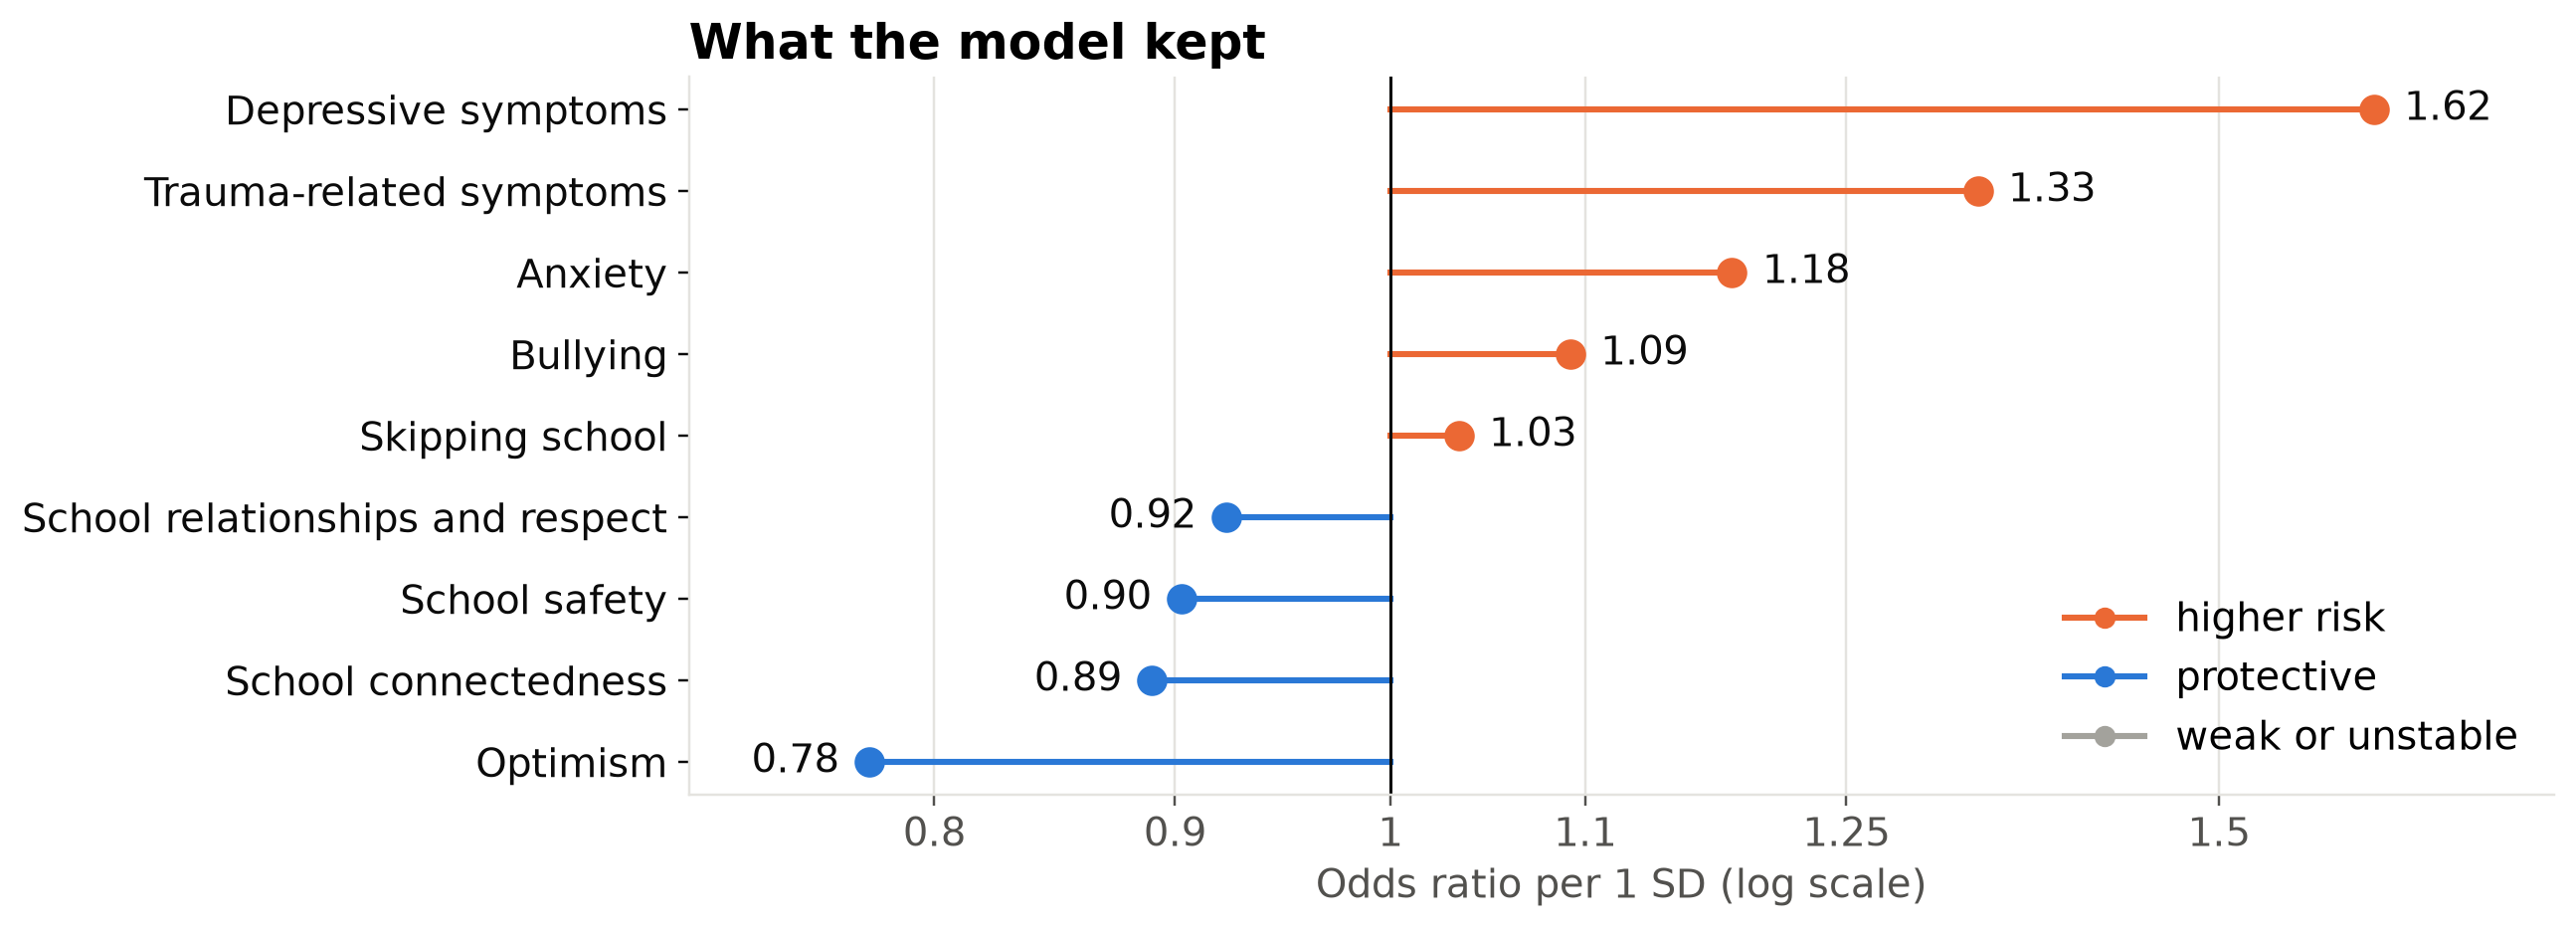

In [14]:
if result["selected_features"]:
    fig.odds_chart(result, labels, pl.classify);

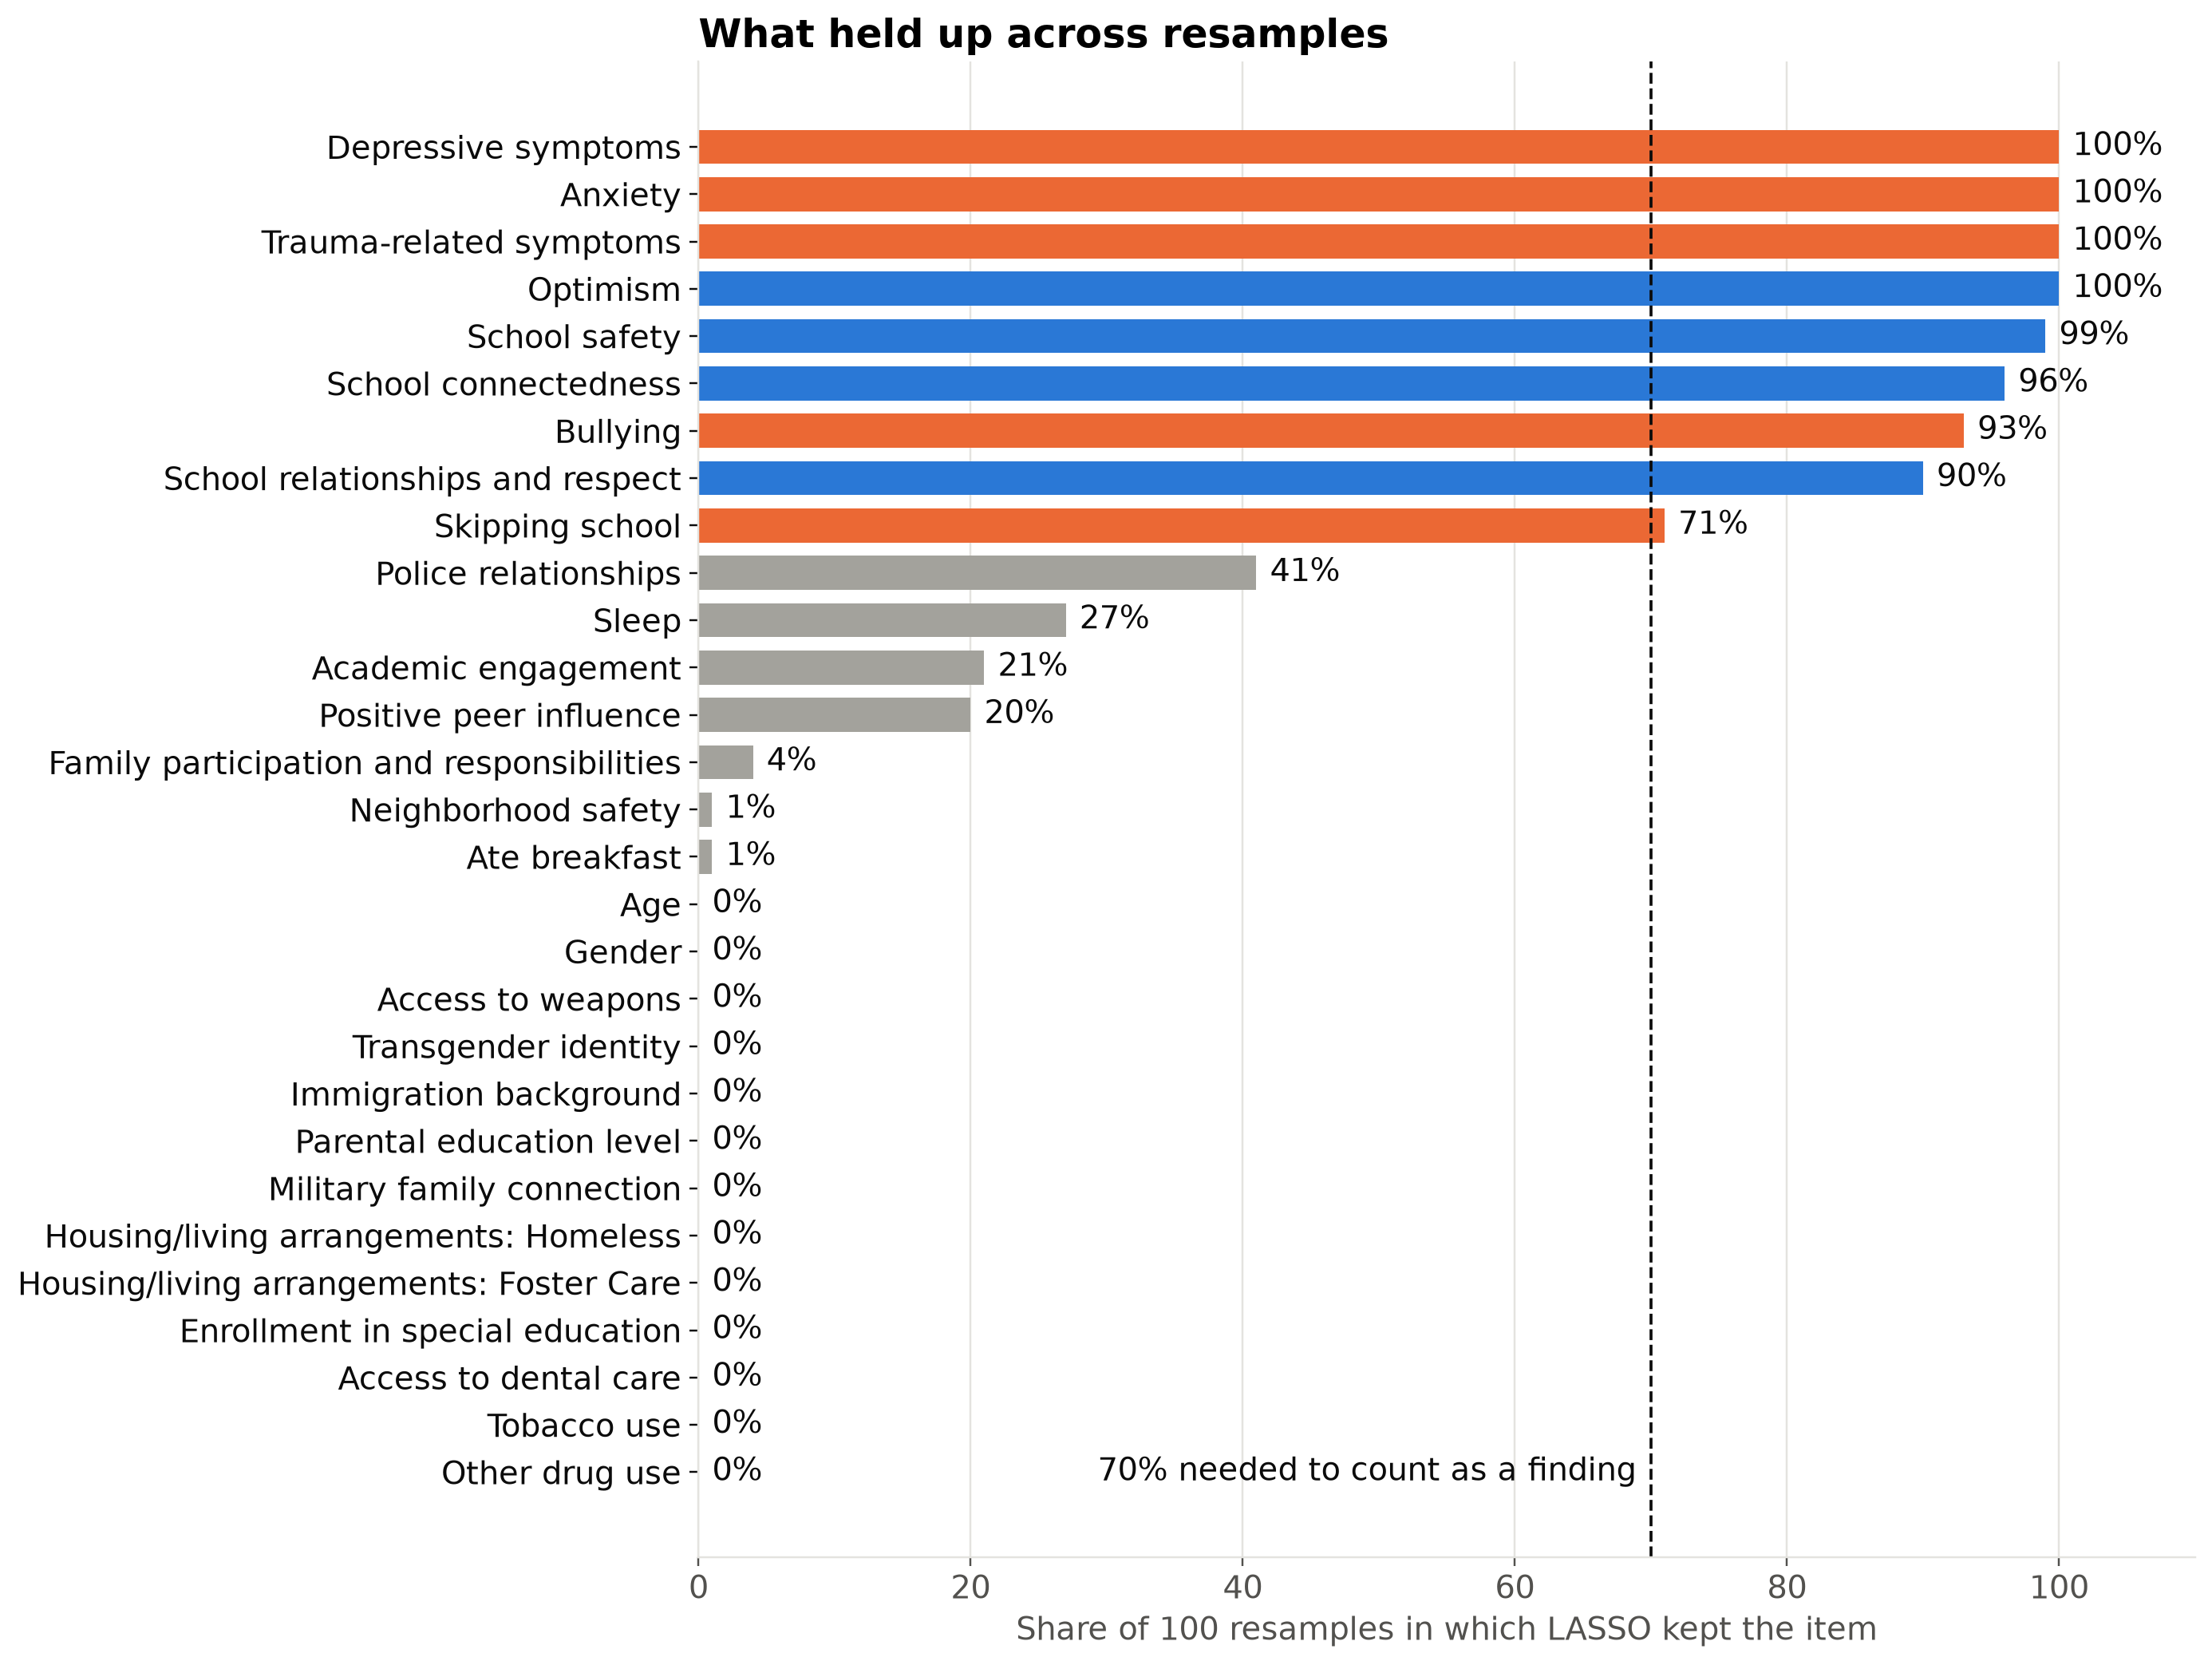

In [15]:
fig.stability_chart(result, labels, pl.classify);

## Calibration

Do predicted risks match observed rates? The published study used a GiViTI calibration belt (`calibrationbelt`), which has no standard Python version. This chart shows the same question using groups of predicted risk, along with a logistic recalibration slope. It is a stand-in, not the same test. A slope above 1 means predictions are too moderate, which a strong penalty tends to produce.

Predictions here come from models that never saw the respondent they're scoring.

Recalibration slope 1.64, intercept 0.37 (perfect: 1 and 0)


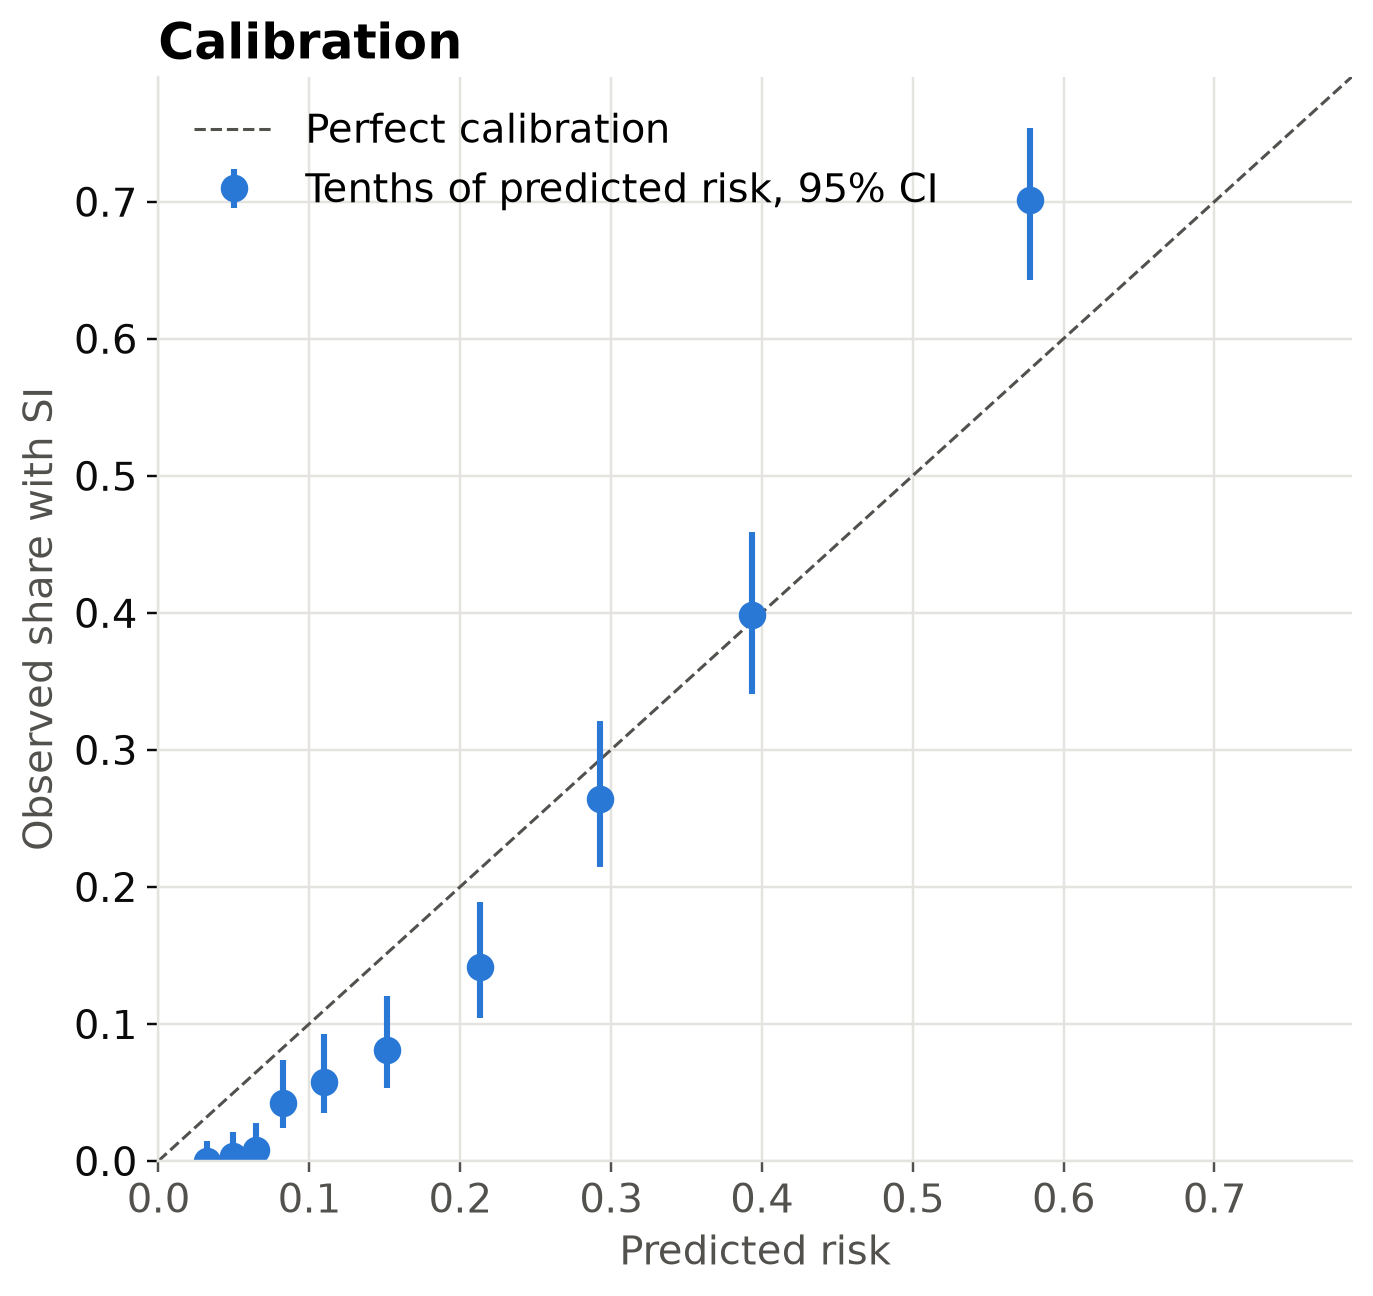

In [16]:
y = df["si"].to_numpy()
room_risk = pl.out_of_fold_risk(df, candidates)
slope = pl.calibration_slope(y, room_risk)
print(f"Recalibration slope {slope['slope']:.2f}, intercept {slope['intercept']:.2f} (perfect: 1 and 0)")
fig.calibration_chart(pl.calibration_table(y, room_risk));

## Validation

10-fold cross-validation with seed 1533, as in `cvauroc`, plus the Brier score. The interval is a percentile bootstrap, while the paper reports a bias-corrected one.

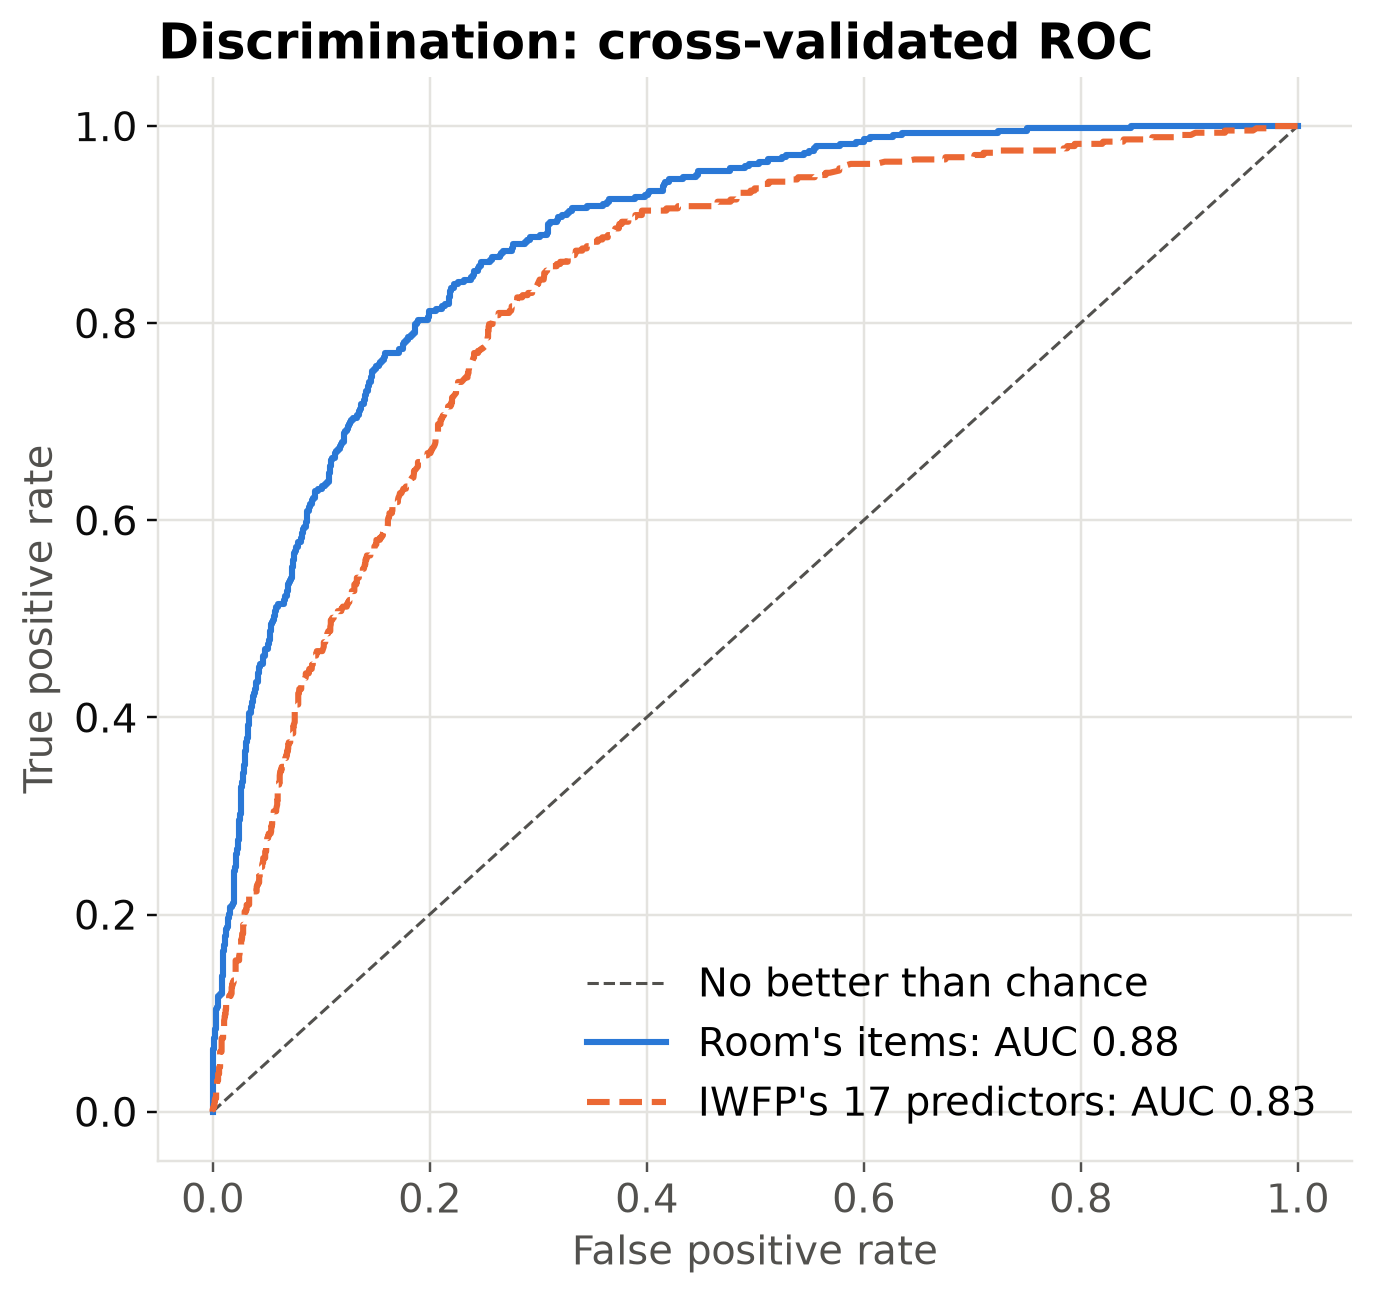

In [17]:
iwfp_items = iwfp.PREDICTORS["item_id"].tolist()
iwfp_result = pl.run_lasso(df, iwfp_items)
iwfp_risk = pl.out_of_fold_risk(df, iwfp_items)
room_perf, iwfp_perf = pl.performance(y, room_risk), pl.performance(y, iwfp_risk)

fig.roc_chart(y, [("Room's items", room_risk, room_perf["auc"]),
                  ("IWFP's 17 predictors", iwfp_risk, iwfp_perf["auc"])]);

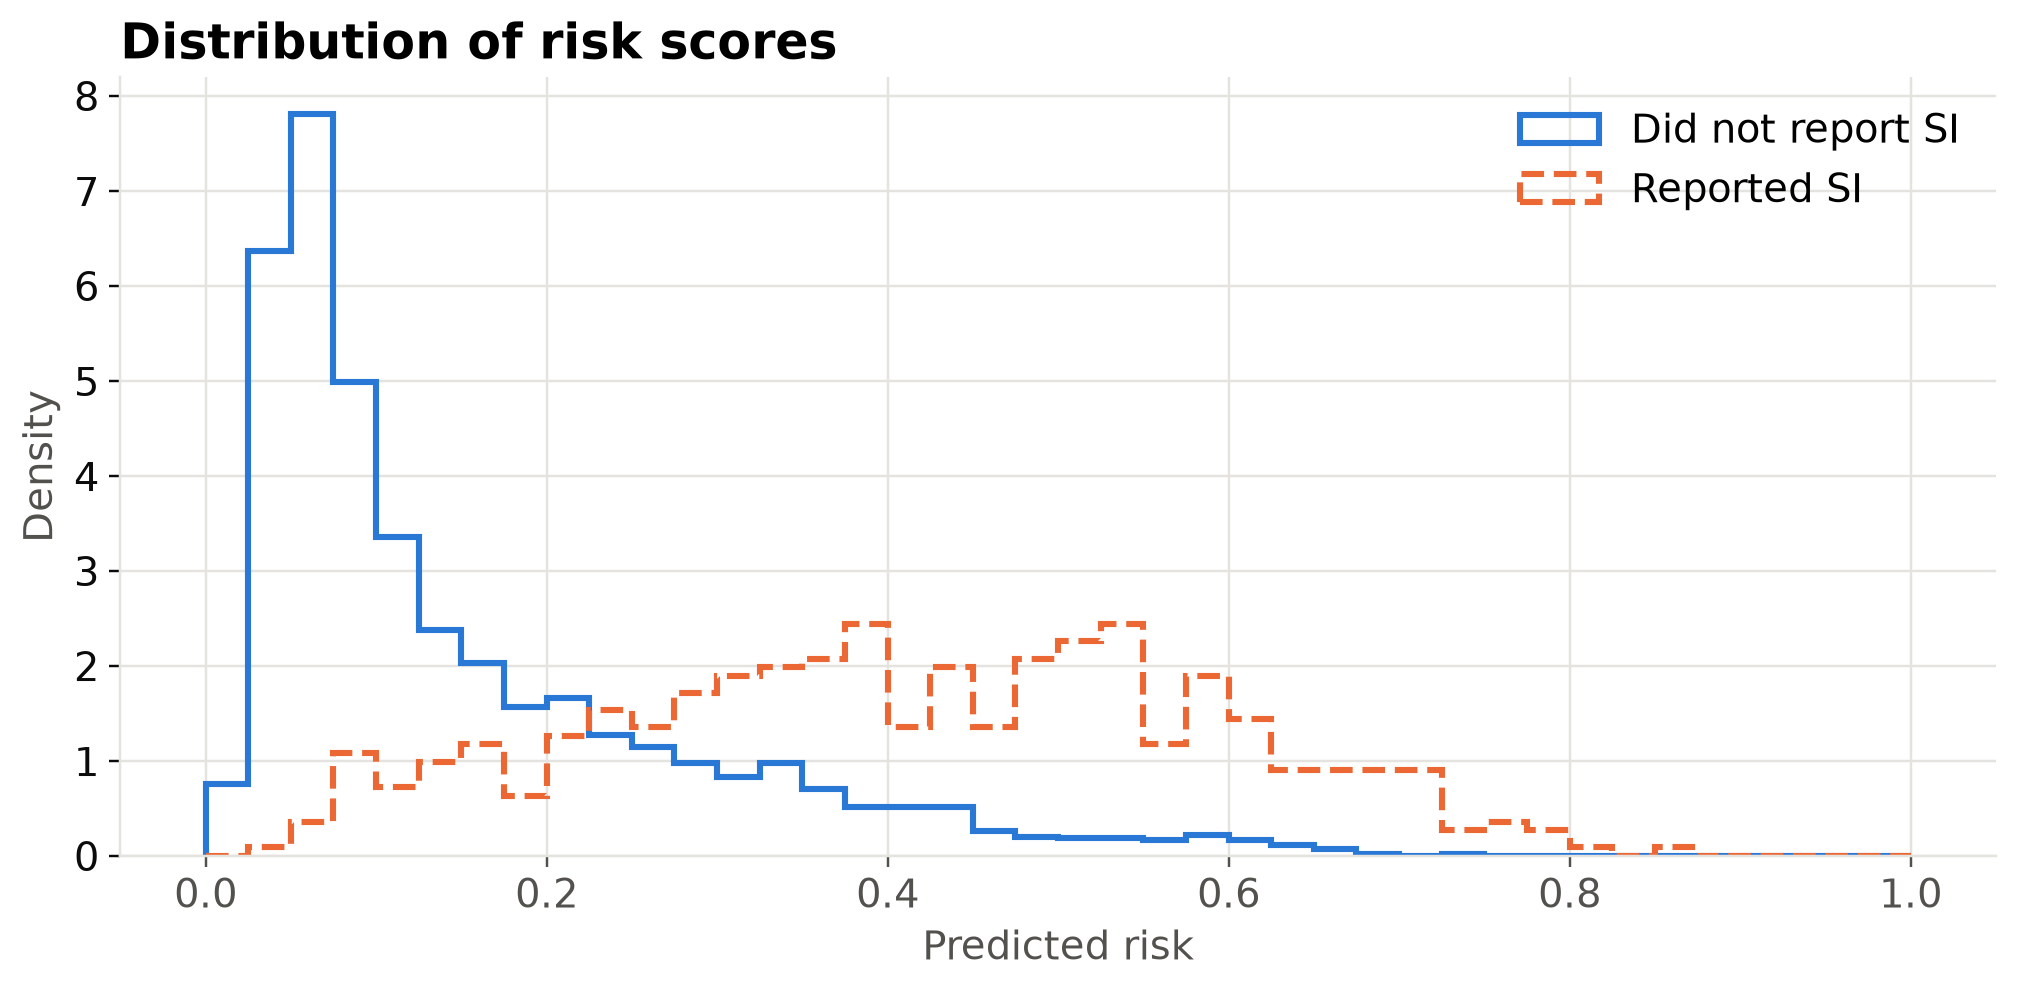

In [18]:
fig.risk_chart(y, room_risk);

# The room's choices next to IWFP's

The first two columns use the same synthetic data, so they compare the predictor sets. The last column is the published model on real CHKS data, shown for reference. **A higher synthetic AUC doesn't mean the room found something the study missed**, because the simulation's settings shape which items predict well.

In [19]:
def describe(offered, retained, perf):
    return {
        "Predictors offered": offered,
        "Predictors retained": retained,
        "Cross-validated AUC (95% CI)": f"{perf['auc']:.2f} ({perf['auc_low']:.2f}, {perf['auc_high']:.2f})",
        "Brier score": f"{perf['brier']:.2f}",
        "Median predicted risk (IQR)": f"{perf['risk_median']:.1%} ({perf['risk_q1']:.1%} to {perf['risk_q3']:.1%})",
    }

pd.DataFrame({
    "Room's items, synthetic": describe(len(candidates), len(result["selected_features"]), room_perf),
    "IWFP's 17, synthetic": describe(17, len(iwfp_result["selected_features"]), iwfp_perf),
    "Published IWFP, real CHKS": describe(17, iwfp.PUBLISHED["predictors retained"], iwfp.PUBLISHED),
})

,"Room's items, synthetic","IWFP's 17, synthetic","Published IWFP, real CHKS"
Predictors offered,29,17,17
Predictors retained,9,6,10
Cross-validated AUC (95% CI),"0.88 (0.87, 0.90)","0.83 (0.81, 0.85)","0.87 (0.84, 0.88)"
Brier score,0.10,0.11,0.10
Median predicted risk (IQR),12.8% (6.5% to 29.2%),9.3% (6.6% to 30.9%),4.8% (2.6% to 26.8%)


# In plain terms

In [20]:
print(pl.format_report(result, labels).split("In plain terms", 1)[-1].split(":", 1)[-1].strip())

Risk factors:       Depressive symptoms, Trauma-related symptoms, Anxiety, Bullying, Skipping school
  Protective factors: Optimism, School connectedness, School safety, School relationships and respect
  The other 20 added little or nothing beyond these, or didn't hold up across resamples.


Questions for the room:

- **LASSO keeps what predicts best, not what matters most for prevention.** What did it drop that you would still act on?
- **Correlated items compete.** Support and connectedness items can split the same signal, so one can look unimportant only because another carried it.
- **What's missing from the board?** The published study had no Spiritual-Historical predictors because of what the survey asked.
- **Who chooses the variables in your own projects, and how could the community?**

# Save this run

In [21]:
from datetime import datetime

stamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")
os.makedirs("results", exist_ok=True)
coef_table.to_csv(f"results/{stamp}_{BOARD_ID}_model_results.csv", index=False)
print(f"Saved results/{stamp}_{BOARD_ID}_model_results.csv")

Saved results/2026-11-03_220008_nov4-rehearsal_model_results.csv
